# Retrieve exoplanet catalogues

Retrieve two datasets from the NASA Exoplanet Archive: confirmed exoplanets and TESS Objects of Interest (TOIs).

These catalogues provide reference information about known planets, candidate planets and their host stars. The records will be used to label TESS observations.

In [1]:

from pathlib import Path
from io import BytesIO

import pandas as pd
import requests
import lightkurve as lk

DATA_DIR = Path("/data/astro-data-lab")

def query_nasa(sql):
    response = requests.get(
        "https://exoplanetarchive.ipac.caltech.edu/TAP/sync",
        params={"query": sql, "format": "csv"},
        timeout=120,
    )
    response.raise_for_status()
    return pd.read_csv(BytesIO(response.content))

confirmed = query_nasa(
    "SELECT tic_id, pl_name, sy_pnum "
    "FROM pscomppars WHERE tic_id IS NOT NULL"
)

tois = query_nasa(
    "SELECT tid, toi, tfopwg_disp "
    "FROM toi WHERE tid IS NOT NULL"
)

print(f"Confirmed planet records: {len(confirmed):,}")
print(f"TOI records: {len(tois):,}")


/home/mark/projects/astro-data-lab/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Confirmed planet records: 6,144
TOI records: 8,151


# Match observations to catalogue records

Use TESS Input Catalog (TIC) identifiers to match stars in our existing MAST inventory against the exoplanet catalogues.

Count the confirmed planets associated with each matched star and identify its candidate status where available.

Select a small sample of known planet hosts, candidate hosts and unclassified stars for testing.

A star with no catalogued planets is not necessarily planet-free.

In [2]:

# Normalise identifiers
confirmed["tic_id"] = pd.to_numeric(
    confirmed["tic_id"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
).astype("Int64")

tois["tic_id"] = pd.to_numeric(
    tois["tid"], errors="coerce"
).astype("Int64")

# Summarise confirmed planets per star
hosts = (
    confirmed.groupby("tic_id")["pl_name"]
    .nunique()
    .reset_index(name="n_confirmed_planets")
)

# Summarise TOI dispositions per star
statuses = (
    tois.groupby("tic_id")["tfopwg_disp"]
    .agg(lambda x: ", ".join(sorted(set(x.dropna()))))
    .reset_index(name="toi_status")
)

# Load our existing Sector 1 inventory
inventory = pd.read_csv(
    DATA_DIR / "metadata/mast/spoc/sector_001_lc.csv"
)

inventory["tic_id"] = pd.to_numeric(
    inventory["productFilename"].str.extract(
        r"-s\d{4}-(\d+)-"
    )[0],
    errors="coerce"
).astype("Int64")

available = inventory["tic_id"].dropna().drop_duplicates()

# Select a few examples of each population
known = available[available.isin(hosts["tic_id"])].head(2)

candidate_ids = tois.loc[
    tois["tfopwg_disp"].eq("PC"), "tic_id"
]
candidates = available[
    available.isin(candidate_ids) &
    ~available.isin(hosts["tic_id"])
].head(2)

unknown = available[
    ~available.isin(hosts["tic_id"]) &
    ~available.isin(tois["tic_id"])
].head(1)

targets = pd.DataFrame({
    "tic_id": pd.concat([known, candidates, unknown]).tolist()
})

# Join observations to catalogue labels
dataset = (
    targets
    .merge(hosts, on="tic_id", how="left")
    .merge(statuses, on="tic_id", how="left")
)

dataset["n_confirmed_planets"] = (
    dataset["n_confirmed_planets"].fillna(0).astype(int)
)

dataset["label"] = "unclassified"
dataset.loc[
    dataset["toi_status"].fillna("").str.contains(r"\bPC\b"),
    "label"
] = "candidate"
dataset.loc[
    dataset["n_confirmed_planets"] > 0,
    "label"
] = "confirmed_host"

display(dataset)


,tic_id,n_confirmed_planets,toi_status,label
0,52368076,3,"CP, PC",confirmed_host
1,234345288,1,"CP, PC",confirmed_host
2,167719618,0,PC,candidate
3,167303382,0,PC,candidate
4,355094959,0,NaN,unclassified


# Download TESS light curves

Search MAST for the selected stars and download their available Sector 1 SPOC light curves.

Store the original observation files on the homelab's data drive and record which targets were downloaded successfully.

This provides real observational data to accompany the catalogue information.

In [3]:

TESS_DIR = DATA_DIR / "raw/tess"
TESS_DIR.mkdir(parents=True, exist_ok=True)

lightcurves = {}

for tic_id in dataset["tic_id"]:
    results = lk.search_lightcurve(
        f"TIC {int(tic_id)}",
        mission="TESS",
        author="SPOC",
        sector=1,
    )

    if len(results) == 0:
        print(f"No Sector 1 light curve: {tic_id}")
        continue

    lc = results[0].download(
        download_dir=str(TESS_DIR)
    )

    if lc is not None:
        lightcurves[int(tic_id)] = lc
        print(f"Downloaded TIC {tic_id}")

dataset["has_lightcurve"] = dataset["tic_id"].isin(lightcurves)

display(dataset)


Downloaded TIC 52368076
Downloaded TIC 234345288
Downloaded TIC 167719618
Downloaded TIC 167303382
Downloaded TIC 355094959


,tic_id,n_confirmed_planets,toi_status,label,has_lightcurve
0,52368076,3,"CP, PC",confirmed_host,True
1,234345288,1,"CP, PC",confirmed_host,True
2,167719618,0,PC,candidate,True
3,167303382,0,PC,candidate,True
4,355094959,0,NaN,unclassified,True


# Inspect the combined dataset

Select one downloaded observation and display its associated catalogue information alongside its light curve.

Check that the observation belongs to the expected star and that the planet labels have been joined correctly.

This validates the basic data-linking approach before we build the full ingestion system.

     tic_id  n_confirmed_planets toi_status           label  has_lightcurve
0  52368076                    3     CP, PC  confirmed_host            True


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

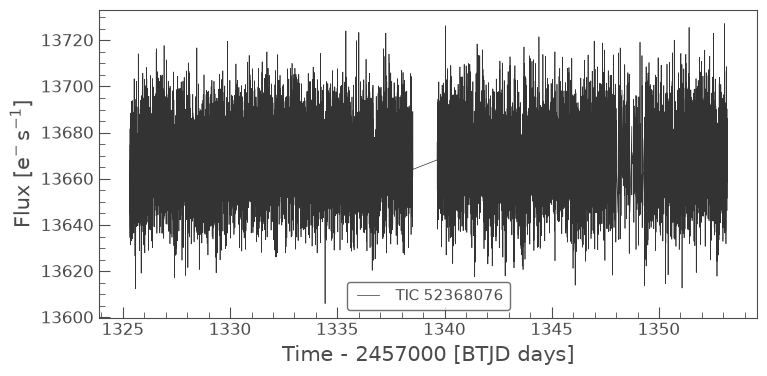

In [4]:

tic_id = next(iter(lightcurves))

print(dataset.loc[dataset["tic_id"] == tic_id])

lightcurves[tic_id].plot()
